In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
root = os.getcwd()
img_path = os.path.join(root, "hpref.tif")
img_gray = cv.imread(img_path, cv.IMREAD_GRAYSCALE)

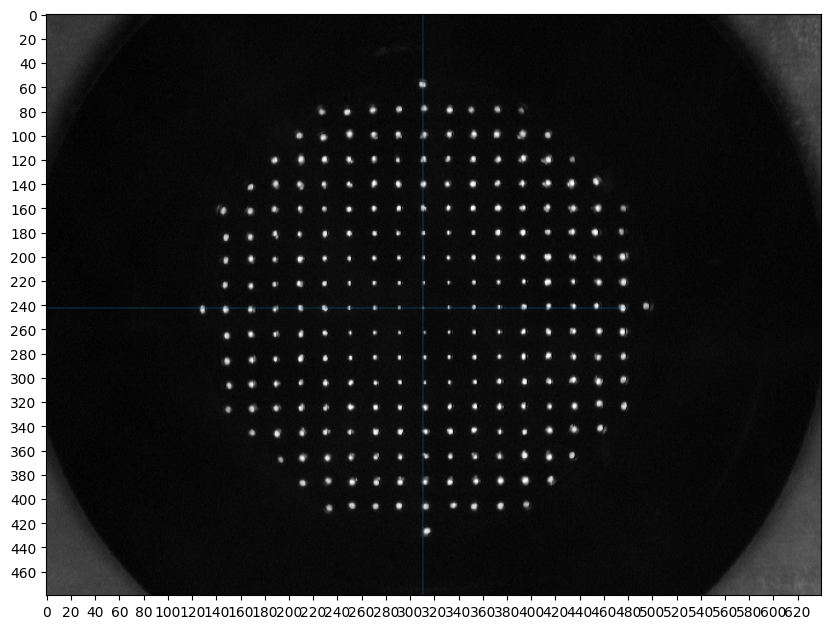

In [3]:
plt.figure(figsize=(10,10))
plt.xticks(np.arange(0,640,20))
plt.yticks(np.arange(0,480,20))
plt.vlines(x=311, ymin=0, ymax=480, lw=0.3)
plt.hlines(y=242, xmin=0, xmax=480, lw = 0.3)
plt.imshow(img_gray, cmap='gray')

In [4]:
h, w = img_gray.shape[:2]
h,w

(480, 640)

In [5]:
#The following code is being built 23/9
centered_img_gray = img_gray[:, 71:551]

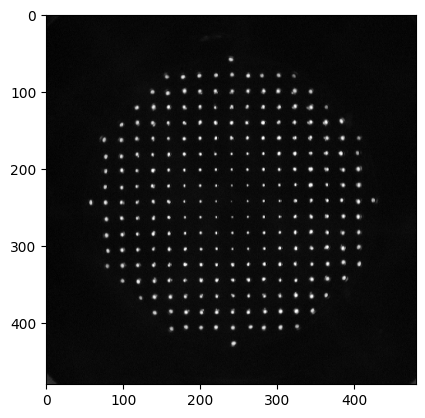

In [6]:
plt.imshow(centered_img_gray, cmap="gray")

In [7]:
centered_img_gray.shape

(480, 480)

In [8]:
out_path = os.path.join(root, "hpref_cropped.tif")
cv.imwrite(out_path, centered_img_gray)
print("Still needs to be fixed, it is not the same")
print("saved to:", out_path)

Still needs to be fixed, it is not the same
saved to: c:\Users\PC\Desktop\UN\OpticsWork\codefiles\thesisreproduction\hpref_cropped.tif


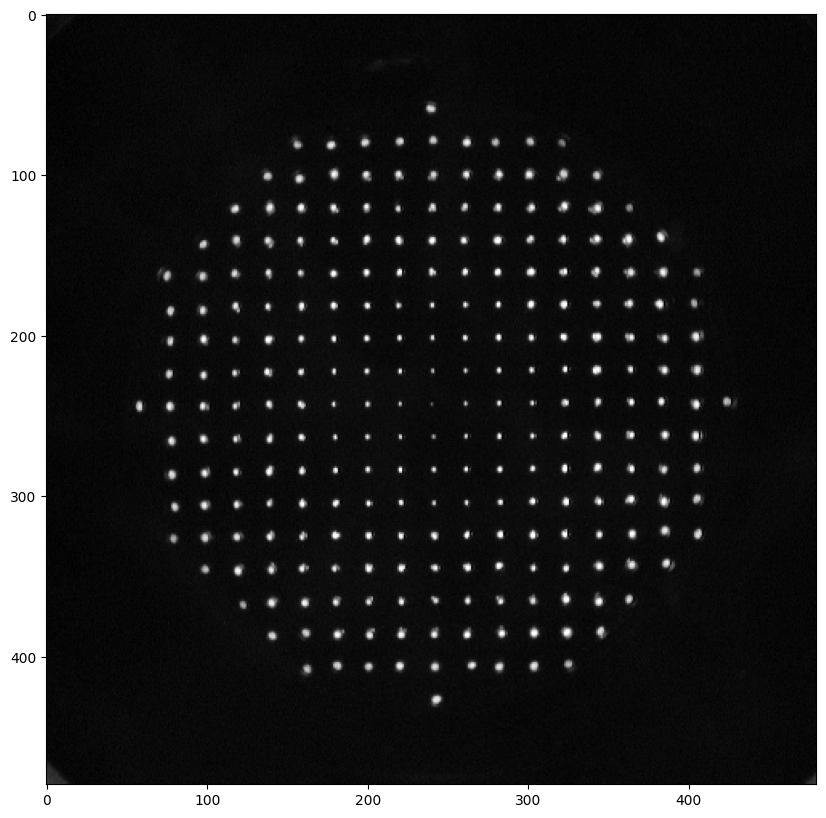

In [9]:
plt.figure(figsize=(10,10))
plt.imshow(centered_img_gray, cmap='gray')

Text(0.5, 1.0, 'Intensities histogram')

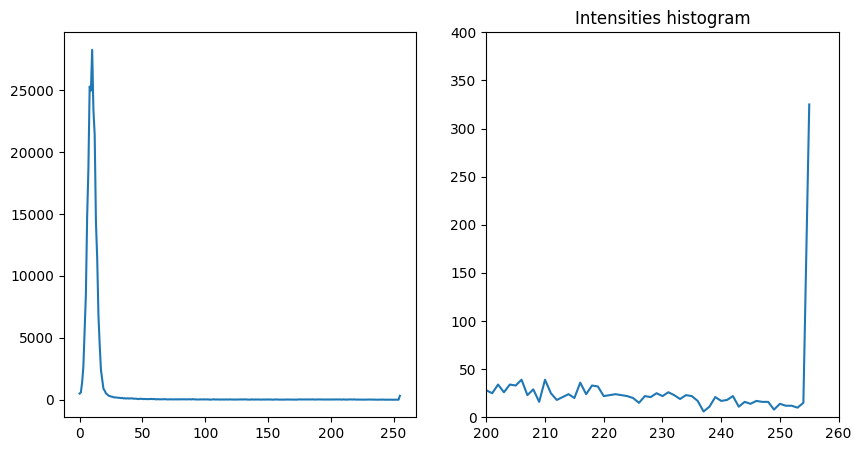

In [10]:
hist = cv.calcHist([centered_img_gray], [0], None, [256], [0,256])
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.plot(hist)


plt.subplot(1,2,2)
plt.plot(hist)
plt.xlim(200,260)
plt.ylim(0,400)

plt.title("Intensities histogram")


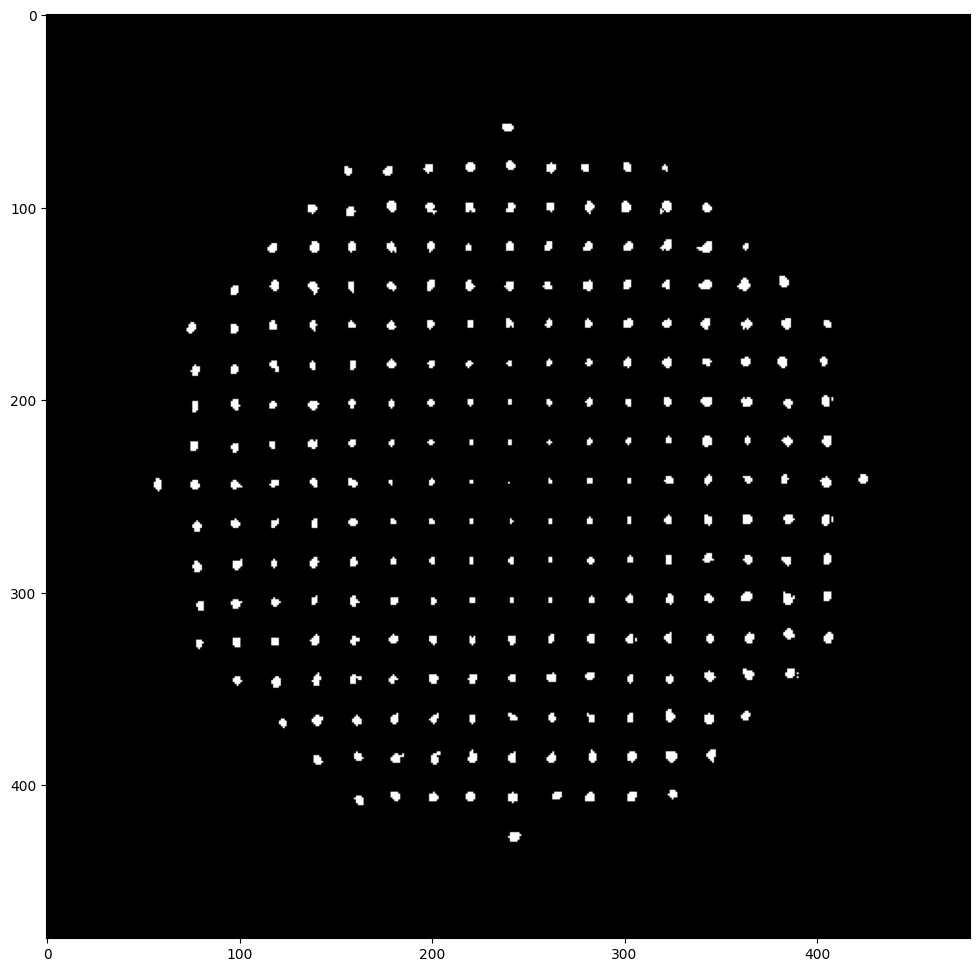

In [11]:
ret,thresh1 = cv.threshold(centered_img_gray,100,255,cv.THRESH_BINARY)
plt.figure(figsize=(12,12))
plt.imshow(thresh1, cmap="gray")

In [12]:
thresh1

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=uint8)

Applying the OTSU algorithm to detect the centroids of the image...

In [13]:
# arb_thres = 255
# max_val = 255

# plt.figure(figsize=(12,12))
# thres, img_otsu = cv.threshold(centered_img_gray, arb_thres, max_val, cv.THRESH_BINARY + cv.THRESH_OTSU)
# plt.imshow(img_otsu, cmap="gray")
# thres

So, we are going to proceed to do the analysis to find the centroids.

In [14]:
#Finding contours in the binarized image:
# contornos, _ = cv.findContours(img_otsu, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
contornos, _ = cv.findContours(thresh1, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

#Array to save the centroids:
centroids_x_coord = []
centroids_y_coord = []


In [15]:
for cnt in contornos:
    area = cv.contourArea(cnt)
    if area > 100:
        #Filtering the contours that are or too large or to small to be assumed as a point with a CM.
        continue
    # Calcular los momentos del contorno para determinar el centroide
    M = cv.moments(cnt)
    if M["m00"] != 0:
        cX = int(M["m10"] / M["m00"])
        cY = int(M["m01"] / M["m00"])
        centroids_x_coord.append(cX)
        centroids_y_coord.append(cY)
    else:
        continue

# 7. Mostrar los resultados
# plt.figure(figsize=(10, 10))
# plt.imshow(cv.cvtColor(img_otsu, cv.COLOR_BGR2RGB))
# plt.title("Detección de Puntos Láser")
# plt.axis('off')
# plt.show()

In [16]:
len(centroids_x_coord)

252

Now we proceed to add the central point

In [17]:
centroids_x_coord.append(240)
centroids_y_coord.append(242)

In [18]:
len(centroids_x_coord), len(centroids_y_coord)

(253, 253)

In [19]:
matA = np.zeros((480,480))

In [20]:
for i in range(253):
    matA[centroids_x_coord[i]][centroids_y_coord[i]] = 1

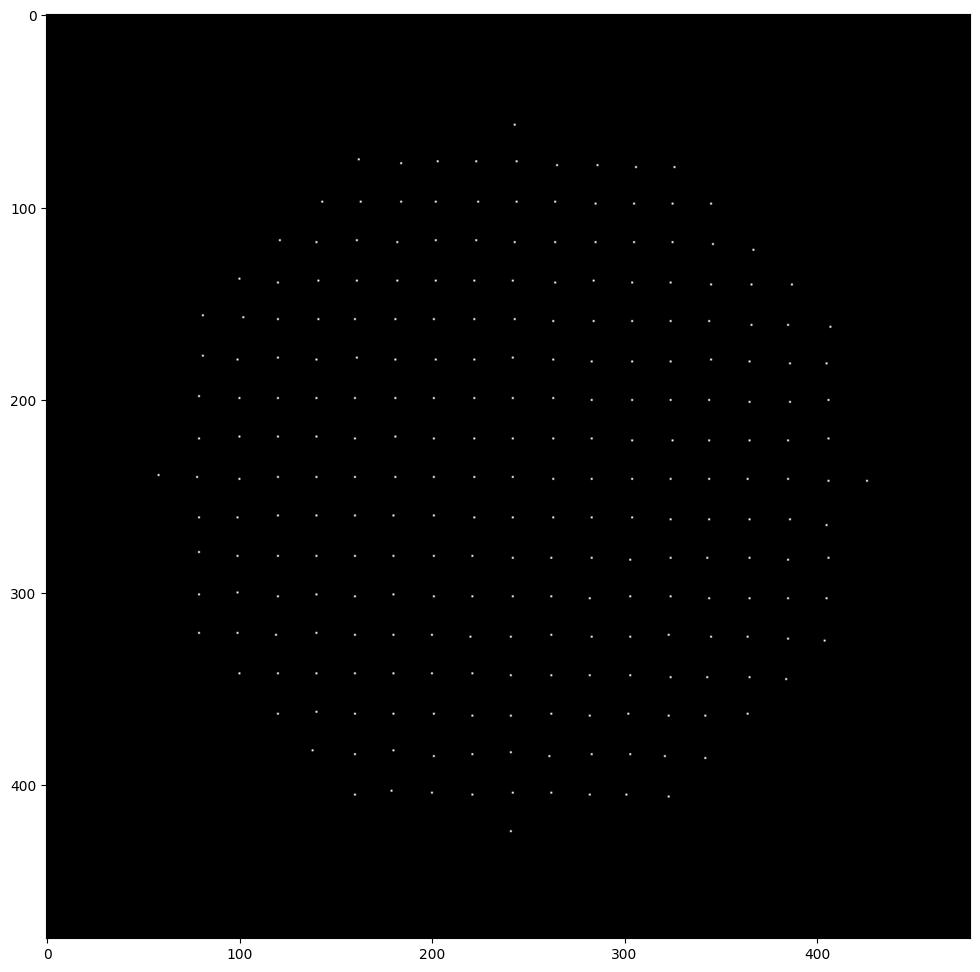

In [21]:
plt.figure(figsize=(12,12))
plt.imshow(matA, cmap="gray")

In [22]:
counter = 1
with open("output.txt", "w") as f:
    for a, b in zip(centroids_x_coord, centroids_y_coord):   # iterate over both arrays at once
        f.write(f"{counter} {b} {a}\n")
        counter += 1

<h2><center> <b> Mask Generator</b> <center>

Now, we are going to proceed to generate a mask of radius three in order to label correctly each one of the points to perform the numerical derivative.

In [23]:
def mask_generator(img_mat, radius):
    centroids = []
    centroids_region = []
    N = 480
    matA_mask = np.zeros_like(img_mat)
    for ii in range(N): #This will help us to iterate across the x-axis (columns)
        for jj in range(N): ##This will help us to iterate across the y-axis (rows)
            if matA[ii][jj] != 0: #Interval to iterate and generate the mask
                centroids.append([ii,jj])
                regional_coords = []
                for kk in range(ii-radius, ii + radius + 1):
                    for ll in range(jj-radius, jj + radius + 1):
                        d = np.sqrt((kk-ii)**2+(ll-jj)**2)
                        if (d <= radius):
                            matA_mask[kk][ll] = 1   
                            regional_coords.append([kk,ll])
                regional_coords.append({'region':0})
                centroids_region.append(regional_coords)
    return matA_mask, centroids, centroids_region

In [24]:
mask_r, centroids, centroids_region = mask_generator(matA, 7)

In [25]:
centroids

[[57, 243],
 [75, 162],
 [76, 203],
 [76, 223],
 [76, 244],
 [77, 184],
 [78, 265],
 [78, 286],
 [79, 306],
 [79, 326],
 [97, 143],
 [97, 163],
 [97, 184],
 [97, 202],
 [97, 224],
 [97, 244],
 [97, 264],
 [98, 285],
 [98, 305],
 [98, 325],
 [98, 345],
 [117, 121],
 [117, 161],
 [117, 202],
 [117, 223],
 [118, 140],
 [118, 182],
 [118, 243],
 [118, 264],
 [118, 285],
 [118, 305],
 [118, 325],
 [119, 346],
 [122, 367],
 [137, 100],
 [138, 141],
 [138, 161],
 [138, 182],
 [138, 202],
 [138, 222],
 [138, 242],
 [138, 284],
 [139, 120],
 [139, 264],
 [139, 304],
 [139, 324],
 [140, 345],
 [140, 366],
 [140, 387],
 [156, 81],
 [157, 102],
 [158, 120],
 [158, 141],
 [158, 160],
 [158, 181],
 [158, 201],
 [158, 222],
 [158, 243],
 [159, 263],
 [159, 284],
 [159, 304],
 [159, 324],
 [159, 344],
 [161, 366],
 [161, 385],
 [162, 407],
 [177, 81],
 [178, 120],
 [178, 161],
 [178, 242],
 [179, 99],
 [179, 140],
 [179, 181],
 [179, 202],
 [179, 222],
 [179, 263],
 [179, 345],
 [180, 283],
 [180, 304

In [26]:
v_initial_cols = np.min(centroids_y_coord)
v_final_cols   = np.max(centroids_y_coord)

v_initial_rows = np.min(centroids_x_coord)
v_final_rows   = np.max(centroids_x_coord)

In [27]:
len(centroids_region[0])

150

In [28]:
centroids_region[2][-1]

{'region': 0}

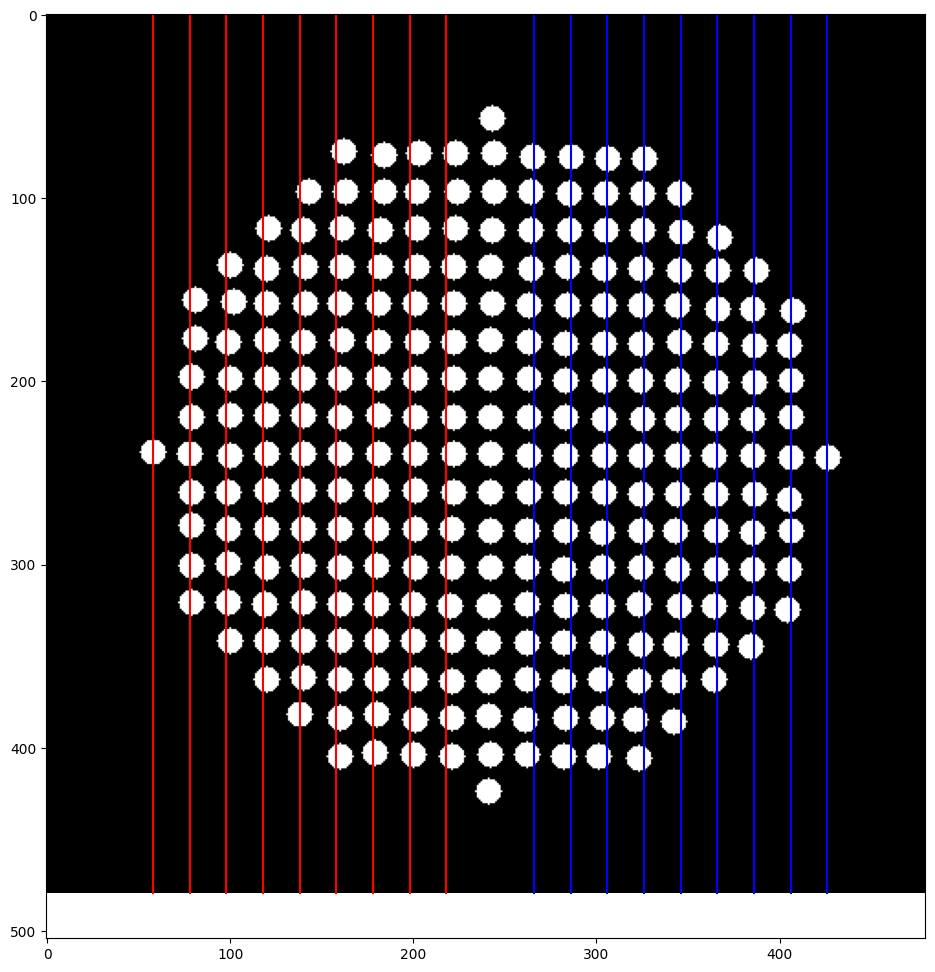

In [29]:
plt.figure(figsize=(12,12))
plt.imshow(mask_r, cmap="gray")

vals_to_iterate = []


for i in range(0,9):
    plt.vlines(x=v_initial_cols+20*i, ymin= 0, ymax=480, color='r')
    vals_to_iterate.append(v_initial_cols+20*i)


for j in range(0, 9):
    plt.vlines(x=v_final_cols-20*j, ymin= 0, ymax=480, color='b')
    vals_to_iterate.append(v_final_cols-20*j)

vals_to_iterate.append(242)

In [30]:
vals_to_iterate = np.sort(vals_to_iterate)

In [31]:
vals_to_iterate

array([ 58,  78,  98, 118, 138, 158, 178, 198, 218, 242, 266, 286, 306,
       326, 346, 366, 386, 406, 426])

In [32]:
label = 1
for ii in vals_to_iterate:
    jj = 0
    while(jj < 480):
        if mask_r[ii][jj] != 0:
            kk = jj + 1
            while(mask_r[ii][kk] != 0):
                kk += 1
            jj = kk - 1
            for mm in centroids_region:
                if ([ii,jj] in mm):
                    mm[-1] = {'region': label}
                    break
            label += 1
        jj += 1

In [33]:
for cc in centroids:
    for rr in centroids_region:
        if cc in rr:
            cc.append(rr[-1]['region'])
            break



In [34]:
centroids

[[57, 243, 1],
 [75, 162, 2],
 [76, 203, 4],
 [76, 223, 5],
 [76, 244, 6],
 [77, 184, 3],
 [78, 265, 7],
 [78, 286, 8],
 [79, 306, 9],
 [79, 326, 10],
 [97, 143, 11],
 [97, 163, 12],
 [97, 184, 13],
 [97, 202, 14],
 [97, 224, 15],
 [97, 244, 16],
 [97, 264, 17],
 [98, 285, 18],
 [98, 305, 19],
 [98, 325, 20],
 [98, 345, 21],
 [117, 121, 22],
 [117, 161, 24],
 [117, 202, 26],
 [117, 223, 27],
 [118, 140, 23],
 [118, 182, 25],
 [118, 243, 28],
 [118, 264, 29],
 [118, 285, 30],
 [118, 305, 31],
 [118, 325, 32],
 [119, 346, 33],
 [122, 367, 34],
 [137, 100, 35],
 [138, 141, 37],
 [138, 161, 38],
 [138, 182, 39],
 [138, 202, 40],
 [138, 222, 41],
 [138, 242, 42],
 [138, 284, 44],
 [139, 120, 36],
 [139, 264, 43],
 [139, 304, 45],
 [139, 324, 46],
 [140, 345, 47],
 [140, 366, 48],
 [140, 387, 49],
 [156, 81, 50],
 [157, 102, 51],
 [158, 120, 52],
 [158, 141, 53],
 [158, 160, 54],
 [158, 181, 55],
 [158, 201, 56],
 [158, 222, 57],
 [158, 243, 58],
 [159, 263, 59],
 [159, 284, 60],
 [159, 304,

In [35]:
label = 1
for ii in vals_to_iterate:
    init = 0.0
    for jj in range(0,480, 1):
        if mask_r[ii][jj] != 0:
            for kk in centroids_region:
                if (ii,jj,0) in kk:
                    for ll in range(len(kk)):
                        kk[ll][2] = label

In [36]:
file_name = "output_organized.txt"
with open(file_name, 'w') as file:
    for item in centroids:
        file.write(str(item[2]) + " " + str(item[0])+ " "+ str(item[1])+ "\n")